In [1]:
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
print(sys.version)
print(os.getcwd())

3.14.0 (v3.14.0:ebf955df7a8, Oct  7 2025, 08:20:14) [Clang 16.0.0 (clang-1600.0.26.6)]
/Users/kailashnah/Documents/Personal/Study Material/Assignments/Unsupervised Machine Learning/final/osmi-clustering/notebooks


## 1. Loading and exploring the dataset

In [2]:
df = pd.read_csv("../data/mental-health-in-tech-2016_20161114.csv")

In [3]:
# shape of the dataset
df.shape

(1433, 63)

In [4]:
# number of self-employed people
df["Are you self-employed?"].value_counts()

Are you self-employed?
0    1146
1     287
Name: count, dtype: int64

In [5]:
employees = df[df["Are you self-employed?"] == 0].copy()
employees["Are you self-employed?"].value_counts()

Are you self-employed?
0    1146
Name: count, dtype: int64

In [6]:
employees.shape

(1146, 63)

## 2. Filtering the dataset
We are filtering the dataset to only include employees since HR of a company is only interested in the mental health of their employees. This means that we will drop columns that don't have answers at all and also the column that states if they're employed or not

In [7]:
employees_clean = employees.dropna(axis=1, how="all")
employees_clean.shape

(1146, 55)

In [8]:
employees.columns.difference(employees_clean.columns)

Index(['Do you believe your productivity is ever affected by a mental health issue?',
       'Do you have medical coverage (private insurance or state-provided) which includes treatment of  mental health issues?',
       'Do you know local or online resources to seek help for a mental health disorder?',
       'If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?',
       'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?',
       'If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?',
       'If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?',
       'If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?'],
      dtype='str')

In [9]:
employees_clean = employees_clean.drop(columns=["Are you self-employed?"])

In [10]:
employees_clean.shape

(1146, 54)

## 3. Exploratory Data Analysis

#### Gettting an overview of all 54 columns

In [11]:
for index, col in enumerate(employees_clean):
    print(f"{index + 1}. {employees_clean[col].value_counts(dropna=False)}")
    print("\n----------------------------------------\n")

1. How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

----------------------------------------

2. Is your employer primarily a tech company/organization?
1.0    883
0.0    263
Name: count, dtype: int64

----------------------------------------

3. Is your primary role within your company related to tech/IT?
NaN    883
1.0    248
0.0     15
Name: count, dtype: int64

----------------------------------------

4. Does your employer provide mental health benefits as part of healthcare coverage?
Yes                                531
I don't know                       319
No                                 213
Not eligible for coverage / N/A     83
Name: count, dtype: int64

----------------------------------------

5. Do you know the options for mental health care available under your employer-provided coverage?
No          

In [12]:
# 26th col (check), 32nd col(check), 40th col needs to be cleaned, 43rd must be cleaned, 47th col has extreme values, 48th col needs to be cleaned, 53 needs cleaning

In [13]:
employees_clean["What is your age?"].describe()

count    1146.000000
mean       33.655323
std        11.703277
min         3.000000
25%        28.000000
50%        32.000000
75%        38.000000
max       323.000000
Name: What is your age?, dtype: float64

#### Visualizing the age distribution of employees

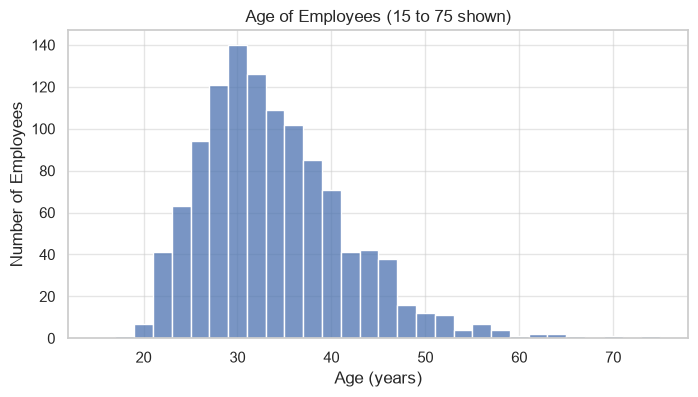

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(data=employees_clean, bins=30, binrange=(15, 75), x="What is your age?")
plt.title("Age of Employees (15 to 75 shown)")
plt.xlabel("Age (years)")
plt.ylabel("Number of Employees")
plt.savefig("../figures/age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
employees_clean["How many employees does your company or organization have?"].value_counts()

How many employees does your company or organization have?
26-100            292
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

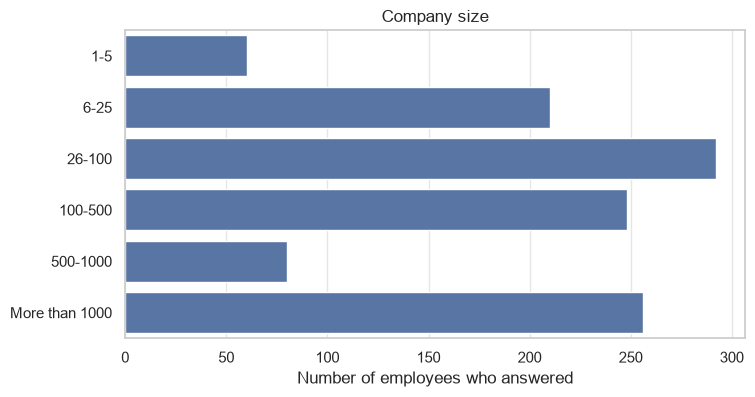

In [16]:
size_order = ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="How many employees does your company or organization have?",
    order=size_order,
)
plt.title("Company size")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/company_size.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
remote_work=employees_clean["Do you work remotely?"].value_counts()
remote_work

Do you work remotely?
Sometimes    611
Never        318
Always       217
Name: count, dtype: int64

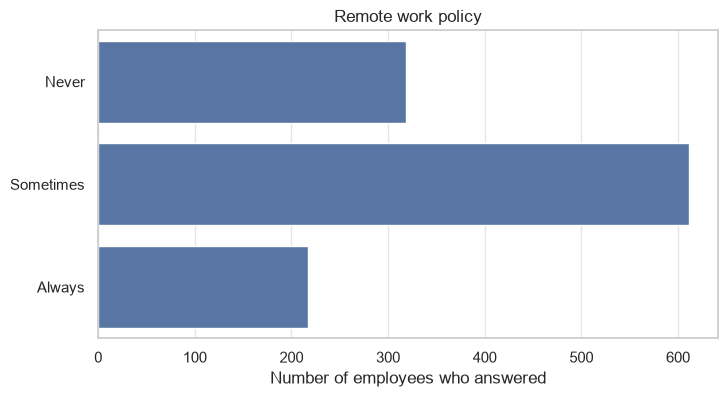

In [18]:
remote_work_order = ["Never", "Sometimes", "Always"]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="Do you work remotely?",
    order=remote_work_order,
)
plt.title("Remote work policy")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/remote_work_policy.png", dpi=150, bbox_inches="tight")
plt.show()

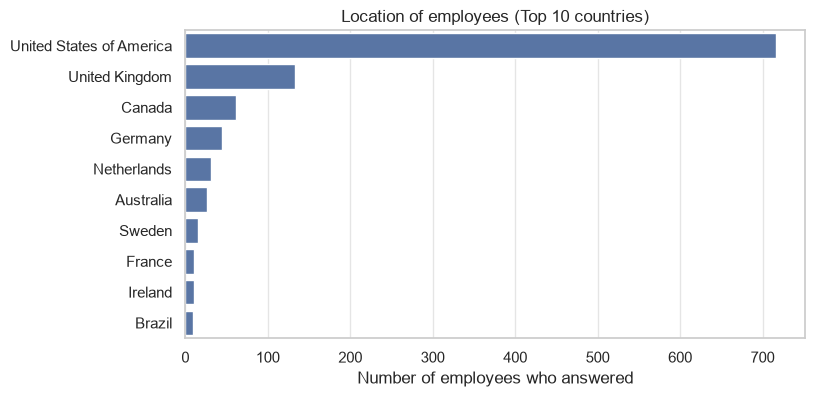

In [19]:
country_order = employees_clean["What country do you work in?"].value_counts().index[:10]

plt.figure(figsize=(8, 4))
sns.countplot(
    data=employees_clean,
    y="What country do you work in?",
    order=country_order,
)
plt.title("Location of employees (Top 10 countries)")
plt.xlabel("Number of employees who answered")
plt.ylabel("")
plt.savefig("../figures/location_employees.png", dpi=150, bbox_inches="tight")
plt.show()